# S08 · Copula 入门：把「边缘」和「依赖」拆开

> **Day 8 / 14** ｜ 对应论文章节 **3.7.1（Copula framework）**
>
> ⚠️ 模拟数据，结果仅用于验证流程。

---

## 学习目标

- 说清楚 copula 到底在分离什么东西
- 用**伪观测（pseudo-observations）**把任意边缘分布变成均匀分布
- 理解为什么 Kendall τ 不受单调变换影响，而 Pearson r 受
- 认识六个常用 copula 族的**形状差异**，并知道热浪问题该关心哪一部分

---

## 1. 一个事件有两个属性，但它们是同一件事

一个热浪事件同时提供：

- `duration` —— 持续多久
- `intensity` —— 峰值超出阈值多少

问题：**这两个量「一起变大」的程度有多强？**

如果只看 `cor(duration, intensity)` 或者两个边缘分布，你答不了这个问题：

```
α 站：duration ~ 3–20 天，intensity ~ 0.5–4 °C      ← 尺度完全不同
β 站：duration ~ 3–12 天，intensity ~ 1–6 °C

怎么比较这两个站的「共同极端程度」？
```

**Copula 的答案**：先把两个量各自变成「在本站分布中的分位」，再在**同一个单位正方形**里比较依赖结构。

---

## 2. 加载数据

In [1]:
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


In [2]:
ev <- load_catalogue()
STATION <- "Kuantan"
DEFN    <- "Tmax"

evx <- ev[ev$station == STATION & ev$defn == DEFN, c("duration", "intensity", "severity")]
evx <- evx[complete.cases(evx), ]

cat("事件数:", nrow(evx), "\n")
print(summary(evx))

事件数: 90 


    duration        intensity        severity      
 Min.   : 3.000   Min.   :0.500   Min.   : 0.9067  
 1st Qu.: 3.000   1st Qu.:1.179   1st Qu.: 2.5350  
 Median : 4.000   Median :1.550   Median : 3.6750  
 Mean   : 4.456   Mean   :1.623   Mean   : 4.3941  
 3rd Qu.: 5.000   3rd Qu.:2.000   3rd Qu.: 5.0650  
 Max.   :13.000   Max.   :3.600   Max.   :16.0767  


---

## 3. 原始尺度：看两个边缘的形状

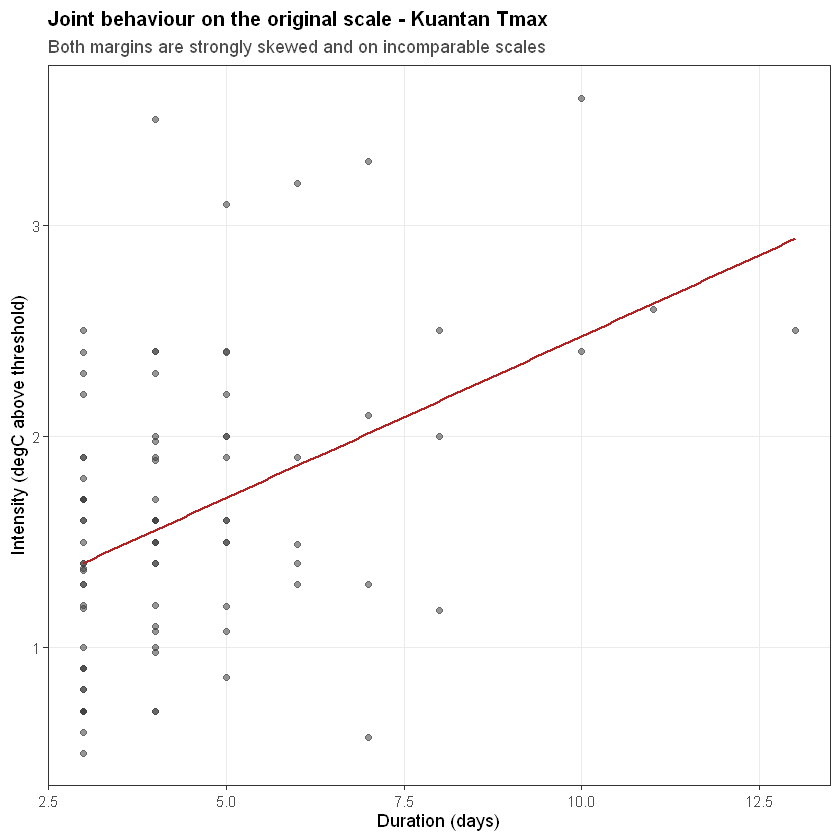

In [3]:
p_raw <- ggplot(evx, aes(duration, intensity)) +
  geom_point(alpha = 0.55, size = 1.7, colour = "grey25") +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE,
              colour = "firebrick", linewidth = 0.7) +
  labs(x = "Duration (days)", y = "Intensity (degC above threshold)",
       title = paste("Joint behaviour on the original scale -", STATION, DEFN),
       subtitle = "Both margins are strongly skewed and on incomparable scales") +
  theme_paper()

save_fig(p_raw, "S08_raw_scatter", 6.5, 4.2)
p_raw

> 🔍 **注意几件事**：
> - `duration` 是**离散**的（3,4,5,…），有很多水平重叠 → 大量平局
> - 两个边缘都右偏
> - 图的形状很大程度上由**边缘**决定，不是由依赖决定

---

## 4. 伪观测：把任何分布压成均匀分布

**概率积分变换（PIT）**：若 $X \sim F$，则 $U = F(X) \sim U(0,1)$。

实践中用**经验分布**代替 $F$：

In [4]:
pit_emp <- function(x) rank(x, ties.method = "average") / (length(x) + 1)

u <- pit_emp(evx$duration)
v <- pit_emp(evx$intensity)

cat("u 的取值范围:", round(range(u), 3), "\n")
cat("均匀性检验 p（duration）:",
    round(suppressWarnings(ks.test(u, "punif"))$p.value, 4), "\n")
cat("均匀性检验 p（intensity）:",
    round(suppressWarnings(ks.test(v, "punif"))$p.value, 4), "\n")

u 的取值范围: 0.198 0.989 


均匀性检验 p（duration）: 0.0017 


均匀性检验 p（intensity）: 0.999 


> 🔍 **注意两个 p 值的巨大差别**：`intensity`（连续）几乎完美均匀，`duration`（离散）却显著偏离。
> 原因不是 PIT 写错了，而是 `duration` 只有 3–13 这么几个取值，`ties.method = "average"`
> 把大量事件压到同一个 `u` 上，形成竖条。
> **这正是 S09 要引入随机化 PIT 的原因** —— 现在先记住这个症状。

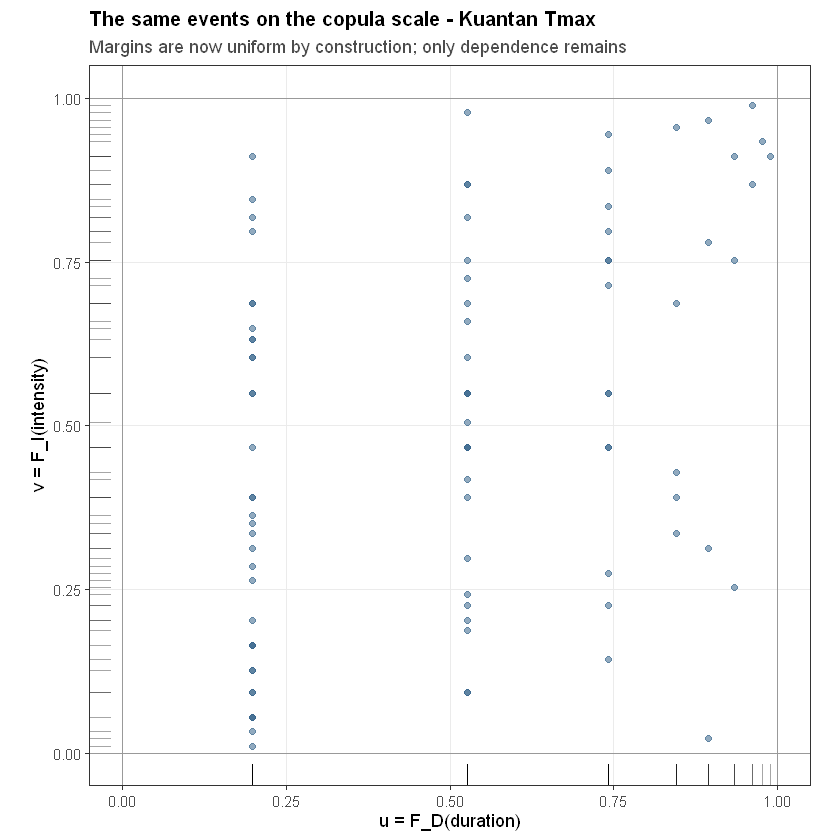

In [5]:
uv <- data.frame(u = u, v = v)

p_cop <- ggplot(uv, aes(u, v)) +
  geom_hline(yintercept = c(0, 1), colour = "grey60") +
  geom_vline(xintercept = c(0, 1), colour = "grey60") +
  geom_point(alpha = 0.55, size = 1.7, colour = "steelblue4") +
  geom_rug(alpha = 0.35) +
  coord_equal(xlim = c(0, 1), ylim = c(0, 1)) +
  labs(x = "u = F_D(duration)", y = "v = F_I(intensity)",
       title = paste("The same events on the copula scale -", STATION, DEFN),
       subtitle = "Margins are now uniform by construction; only dependence remains") +
  theme_paper()

save_fig(p_cop, "S08_copula_scale", 5.6, 5)
p_cop

> 📌 **这就是 Sklar 定理的全部内容**：
> $$F(x,y) = C\big(F_X(x),\, F_Y(y)\big)$$
> 边缘 $F_X, F_Y$ 负责「多大算大」，copula $C$ 负责「两个大是不是一起大」。
> **在 copula 尺度上，所有站点、所有定义的图都可以直接比较。**
>
> ⚠️ 注意 `ties.method = "average"`：`duration` 有大量平局，平局会被赋同一个 `u`。
> 这对连续变量没问题，但对离散变量会让 `u` 出现竖条 —— S09 会用**随机化 PIT** 修掉它。

---

## 5. 相关性的两种度量：只有一种是不变的

In [6]:
# 下面两个变换都是严格单调递增：duration^3 和 exp(intensity)
d2 <- evx$duration^3
i2 <- exp(evx$intensity)

cat(sprintf("Pearson  原始   : %.3f\n", cor(evx$duration, evx$intensity)))
cat(sprintf("Pearson  变换后 : %.3f   <-- 变了\n", cor(d2, i2)))
cat(sprintf("Spearman 原始   : %.3f\n", cor(evx$duration, evx$intensity, method = "spearman")))
cat(sprintf("Spearman 变换后 : %.3f   <-- 不变\n",
            cor(d2, i2, method = "spearman")))
cat(sprintf("Kendall  原始   : %.3f\n", cor(evx$duration, evx$intensity, method = "kendall")))
cat(sprintf("Kendall  变换后 : %.3f   <-- 不变\n",
            cor(d2, i2, method = "kendall")))

Pearson  原始   : 0.437


Pearson  变换后 : 0.369   <-- 变了


Spearman 原始   : 0.381


Spearman 变换后 : 0.381   <-- 不变


Kendall  原始   : 0.295


Kendall  变换后 : 0.295   <-- 不变


> 🔍 **这是 copula 建模选择 Kendall τ 作为目标的根本原因。**
> Pearson 依赖边缘分布的尺度和形状 —— 换个单位、取个立方、取个指数，它就变了（上面从 0.44 掉到 0.37）。
> Kendall τ 和 Spearman ρ 只看**排序是否一致**：排序不变，它们就完全不变。
> 只要变换是**严格单调递增**的（`^3`、`exp`、`log`），排序不变，τ 就不变。
>
> 这也解释了为什么两个站可以直接比 τ：即使甲站的 duration 分布和乙站完全不同，
> τ 衡量的都是「长事件是否倾向于是强事件」这个与尺度无关的问题。
>
> **写进论文**：「Dependence is quantified by Kendall's τ, which is invariant under strictly increasing
> transformations of the margins (Nelsen, 2006), allowing comparison across stations with different
> climatological scales.」

---

## 6. 六个 copula 族：同一个 τ，不同的形状

In [7]:
tau_hat <- cor(evx$duration, evx$intensity, method = "kendall")
cat("本格子的 Kendall tau =", round(tau_hat, 3), "\n")

make_cop <- function(fam, par) switch(fam,
  Gaussian = copula::normalCopula(par, dim = 2),
  t        = copula::tCopula(par, dim = 2, df = 4),
  Clayton  = copula::claytonCopula(par, dim = 2),
  Gumbel   = copula::gumbelCopula(par, dim = 2),
  Frank    = copula::frankCopula(par, dim = 2),
  Joe      = copula::joeCopula(par, dim = 2))

FAMS <- c("Gaussian", "t", "Clayton", "Gumbel", "Frank", "Joe")

# 每个族创建一个"合法的默认参数"对象，只用来调用 iTau() 反解参数
# （Gumbel 的 alpha 必须 ≥ 1，随便填 0.5 会让构造函数直接报错）
base_cop <- list(
  Gaussian = copula::normalCopula(0.5, dim = 2),
  t        = copula::tCopula(0.5, dim = 2, df = 4),
  Clayton  = copula::claytonCopula(1, dim = 2),
  Gumbel   = copula::gumbelCopula(2, dim = 2),
  Frank    = copula::frankCopula(2, dim = 2),
  Joe      = copula::joeCopula(2, dim = 2)
)

sim_list <- lapply(FAMS, function(f) {
  par <- tryCatch(copula::iTau(base_cop[[f]], tau_hat), error = function(e) NA_real_)
  if (is.na(par)) return(NULL)
  cp2 <- make_cop(f, par)
  data.frame(family = f, copula::rCopula(500, cp2))
})
sim_df <- do.call(rbind, sim_list)
names(sim_df)[2:3] <- c("u", "v")

print(table(sim_df$family))

本格子的 Kendall tau = 0.295 



 Clayton    Frank Gaussian   Gumbel      Joe        t 
     500      500      500      500      500      500 


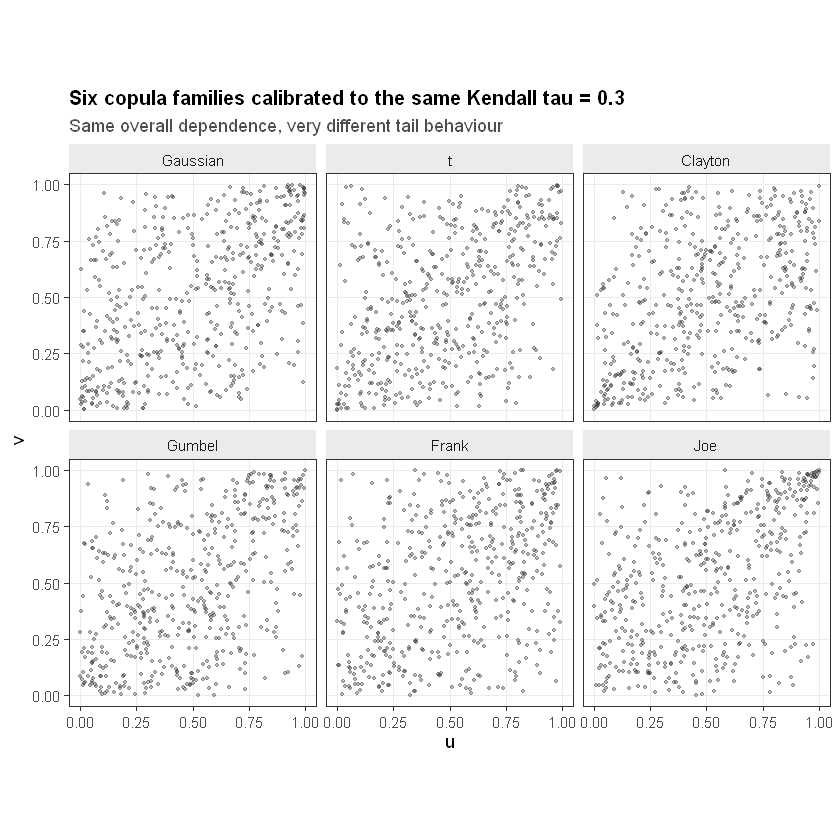

In [8]:
p_fam <- ggplot(sim_df, aes(u, v)) +
  geom_point(alpha = 0.35, size = 0.9, colour = "grey20") +
  facet_wrap(~factor(family, levels = FAMS), nrow = 2) +
  coord_equal(xlim = c(0, 1), ylim = c(0, 1)) +
  labs(x = "u", y = "v",
       title = paste("Six copula families calibrated to the same Kendall tau =",
                     round(tau_hat, 2)),
       subtitle = "Same overall dependence, very different tail behaviour") +
  theme_paper() +
  theme(panel.grid.minor = element_blank())

save_fig(p_fam, "S08_family_shapes", 8, 5.6)
p_fam

> 🔍 **盯住四个角看**，那才是热浪研究真正关心的地方：
>
> | 族 | 左下角 | 右上角 | 含义 |
> |---|---|---|---|
> | **Gaussian** | 空 | 空 | 无尾部依赖 —— 极端事件**不**同时发生 |
> | **t** | 有 | 有 | 双尾对称依赖 |
> | **Clayton** | 挤 | 空 | 一起「小」，不一起「大」 |
> | **Gumbel** | 空 | 挤 | 一起「大」 —— **热浪问题的候选** |
> | **Joe** | 空 | 更挤 | 上尾更强 |
> | **Frank** | 空 | 空 | 全依赖域无尾 |
>
> **一篇做极端事件的论文，如果只拟合 Gaussian copula 而不看尾部依赖，等于主动放弃了核心问题。**

---

## 7. 把数据叠上去

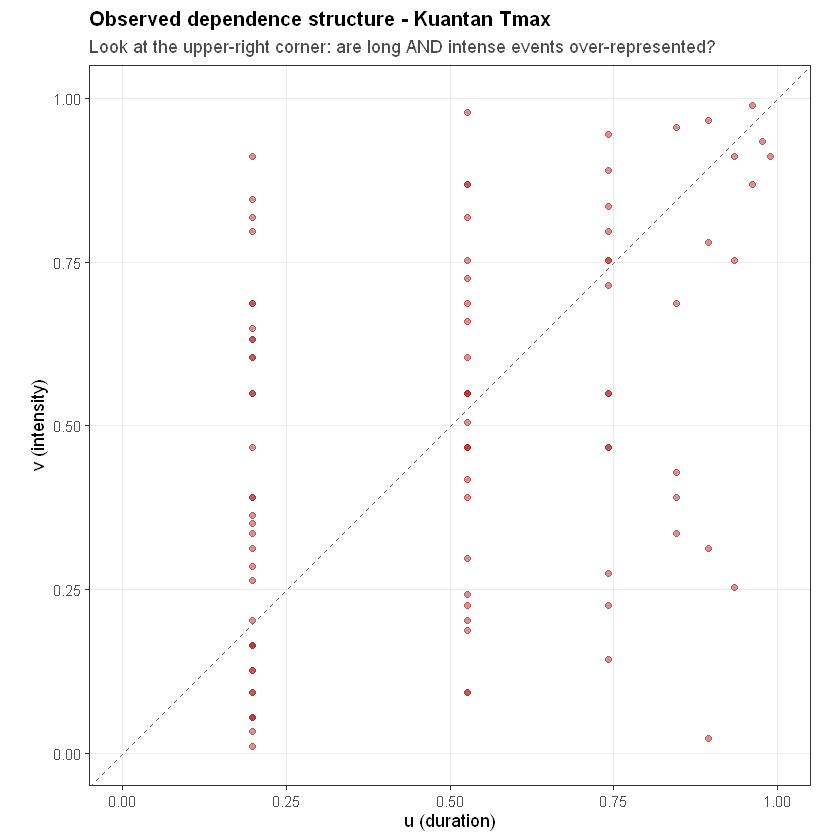

In [9]:
p_over <- ggplot(uv, aes(u, v)) +
  geom_point(alpha = 0.5, size = 1.6, colour = "firebrick") +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey40") +
  coord_equal(xlim = c(0, 1), ylim = c(0, 1)) +
  labs(x = "u (duration)", y = "v (intensity)",
       title = paste("Observed dependence structure -", STATION, DEFN),
       subtitle = "Look at the upper-right corner: are long AND intense events over-represented?") +
  theme_paper()

save_fig(p_over, "S08_observed_tail", 5.6, 5)
p_over

In [10]:
# 定量：右上角（双双极端）实际有多少？
both_hi  <- mean(u > 0.8 & v > 0.8)
indep_hi <- 0.2 * 0.2
cat(sprintf("u>0.8 且 v>0.8 的比例 : %.4f\n", both_hi))
cat(sprintf("若独立应约为           : %.4f\n", indep_hi))
cat(sprintf("富集倍数               : %.2f\n", both_hi / indep_hi))

u>0.8 且 v>0.8 的比例 : 0.0778


若独立应约为           : 0.0400


富集倍数               : 1.94


> 📌 这个「富集倍数」是最朴素的尾部依赖观察。
> 但 n 只有几十个事件，`u>0.8` 的格子只有几个点 —— **这一格的比例极不稳定**。
> S10 会用正式的**尾部依赖系数** λ 和 bootstrap 区间来处理。

---

## 8. 本讲的三个结论

1. Copula 把联合分布拆成「边缘 × 依赖」，让不同站点、不同定义的依赖结构可以比较
2. 用经验 PIT 得到伪观测，不需要对边缘做任何分布假设
3. 依赖用 Kendall τ 度量，因为它对单调变换不变；**尾部依赖才决定极端事件是否同时发生**

---

## 9. 常见错误

| 错误 | 后果 |
|---|---|
| 在原始尺度上比较不同站的相关系数 | 被边缘分布的形状和尺度混淆 |
| 用 `rank(x)/n` 而不是 `/(n+1)` | 出现 1.0，logit/逆变换时爆炸 |
| 忽略平局 | 离散变量的 u 出现竖条，拟合有偏 |
| 只拟合 Gaussian 或 Frank | 结构上不可能有尾部依赖，结论必然是「无」 |
| 用 Pearson 选 copula | 与 copula 的参数含义不一致 |

---

## 10. 自检问题

<details>
<summary>Q1：为什么伪观测用 rank/(n+1) 而不是 rank/n？</summary>

`rank/n` 的最大值是 1，而 $U=1$ 对应 $F^{-1}(1)=\infty$。任何逆变换、logit 或数值优化碰到 1 都会出问题。`/(n+1)` 保证 $u \in (0,1)$。

</details>

<details>
<summary>Q2：如果数据的 τ = 0，还需要 copula 吗？</summary>

需要。τ = 0 只说明**整体**无序关系，不代表尾部也独立。某些 copula（如 t、部分 Frank 参数）可以在 τ ≈ 0 时仍有尾部依赖。热浪问题恰恰关心尾部，所以更要做。

</details>

<details>
<summary>Q3：为什么说 Gaussian copula「没有尾部依赖」？</summary>

Gaussian copula 的尾部依赖系数恒为 λ = 0（除非 ρ = 1）。直观上：二元正态的等高线在极端处变成椭圆，两个变量不会同时冲到极端。这是它被广泛误用于极端事件分析的原因。

</details>

<details>
<summary>Q4：duration 是离散的，用连续 copula 会不会错？</summary>

会有偏（tie 造成的伪依赖），标准做法是**随机化 PIT**：把平局随机分配到 $[a/(n+1), b/(n+1)]$ 区间内。S09 会完整实现。另一种做法是用离散 copula，但参数估计更麻烦。

</details>

---

## 下一步

**S09 · 边缘分布与 PIT**：伪观测只是「用经验分布」，正式建模需要**参数化边缘 + 随机化 PIT**。
这一讲解决离散变量的平局问题，并建立边缘选择的流程。